# 02 — Exploración de producción

Punto de partida para analizar cada pozo. Ejecutar primero la revisión de datos. No se imputan faltantes ni se eliminan paradas.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "data" / "raw").is_dir(), "Abrir desde la raíz del proyecto o notebooks/."
ARCHIVO = ROOT / "data" / "raw" / "Volve production data.xlsx"

# Los identificadores se conservan como texto.
diario = pd.read_excel(ARCHIVO, sheet_name="Daily Production Data", dtype={
    "NPD_WELL_BORE_CODE": "string", "NPD_FIELD_CODE": "string", "NPD_FACILITY_CODE": "string"
})
diario["DATEPRD"] = pd.to_datetime(diario["DATEPRD"], errors="raise")
mensual = pd.read_excel(ARCHIVO, sheet_name="Monthly Production Data", skiprows=[1],
                        na_values=["NULL"], dtype={"NPDCode": "string"})


In [2]:
import matplotlib.pyplot as plt

produccion = diario.loc[diario["FLOW_KIND"].eq("production")].copy()
pozos = sorted(produccion["NPD_WELL_BORE_NAME"].unique())
print("Pozos con registros de producción:", pozos)

Pozos con registros de producción: ['15/9-F-1 C', '15/9-F-11', '15/9-F-12', '15/9-F-14', '15/9-F-15 D', '15/9-F-5']


## Seleccionar un pozo

In [3]:
POZO = "15/9-F-12"
serie = (produccion.loc[produccion["NPD_WELL_BORE_NAME"].eq(POZO)]
         .sort_values("DATEPRD").set_index("DATEPRD"))
assert not serie.empty, "Seleccionar un pozo con registros de producción."
assert serie.index.is_unique, "Revisar duplicados antes de graficar."
# Reindexar sólo para el gráfico: los huecos quedan vacíos, sin interpolación.
serie_calendario = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="D"))
display(serie[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "ON_STREAM_HRS"]].describe())

,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,ON_STREAM_HRS
count,3056.000000,3056.000000,3056.000000,3056.00000
mean,1498.563334,218436.609300,2236.034152,21.33641
std,1662.851799,235250.885353,1952.408547,6.88915
min,0.000000,0.000000,-457.840000,0.00000
25%,266.222500,41004.987500,156.872500,24.00000
50%,697.655000,107734.345000,1349.840000,24.00000
75%,2404.467500,344820.467500,4397.452500,24.00000
max,5901.840000,851131.520000,8019.740000,25.00000


## Evolución temporal

Los volúmenes se muestran en la unidad registrada; su unidad diaria está pendiente de confirmar en el diccionario.

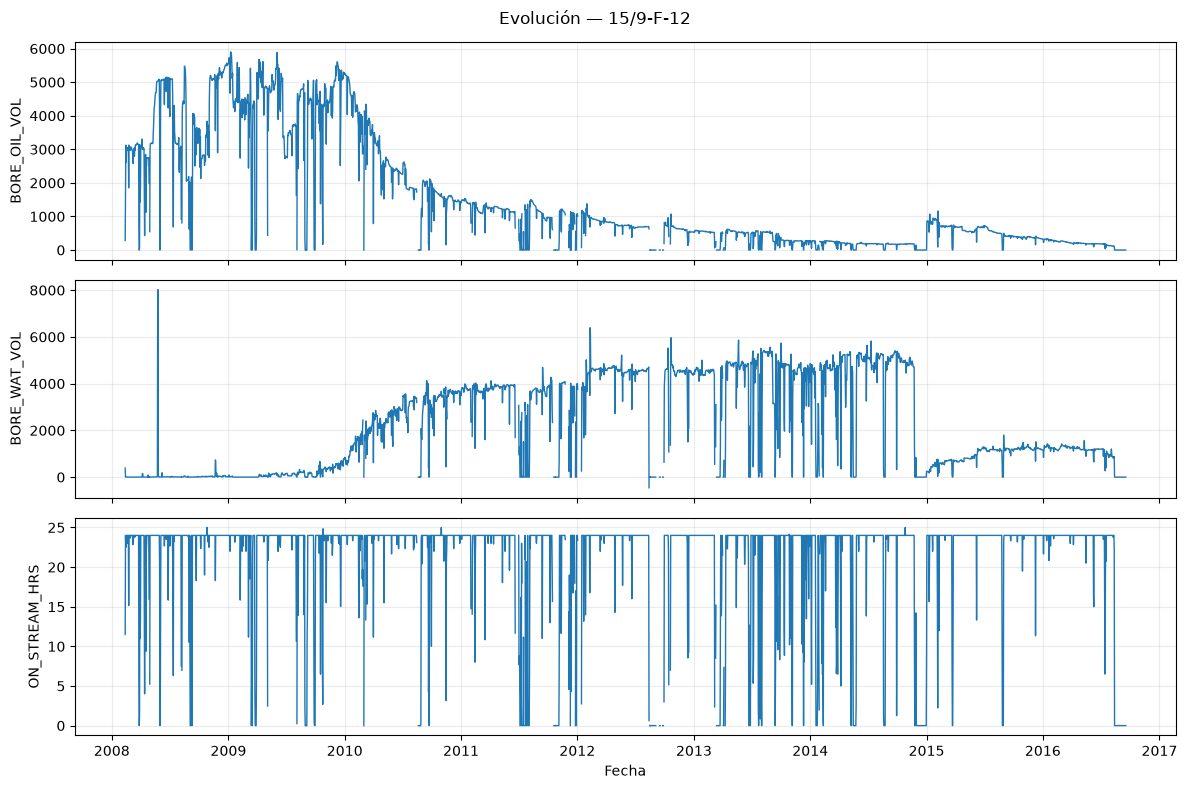

In [4]:
columnas = ["BORE_OIL_VOL", "BORE_WAT_VOL", "ON_STREAM_HRS"]
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, columna in zip(axes, columnas):
    ax.plot(serie_calendario.index, serie_calendario[columna], linewidth=1)
    ax.set_ylabel(columna)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Fecha")
fig.suptitle(f"Evolución — {POZO}")
fig.tight_layout()
plt.show()

## Preguntas para continuar

- ¿Cuándo cambia el comportamiento productivo?
- ¿Qué relación se observa con las horas operativas?
- ¿Qué sensores tienen información suficiente en cada período?
- ¿Qué diferencias aparecen al seleccionar otro pozo?

Registrar asociaciones sin interpretarlas como efectos causales.

## Conclusiones

Completar después de explorar los pozos.